# 3. Real-World Dataset — Wholesale Customers (DBSCAN)

**Owner:** Evelyn

This section applies **DBSCAN** to the Wholesale Customers dataset (UCI) to test whether the behaviour observed on the synthetic benchmarks (Section 2) holds on real, messy, unlabelled business data.

### Dataset

- 440 clients of a wholesale distributor in Portugal
- 6 numeric features: annual spending (monetary units) on **Fresh, Milk, Grocery, Frozen, Detergents_Paper, Delicatessen**
- 2 categorical columns: **Channel** (1 = Horeca: hotels/restaurants/cafés, 2 = Retail) and **Region** (Lisbon / Oporto / Other)

### Evaluation set-up

The dataset has **no true cluster labels**. To still compute the external metrics (ARI, NMI), **Channel is used as a proxy ground truth** — Horeca and Retail clients are known to buy differently, so a good clustering of spending behaviour should partly recover Channel. Channel is **never** given to DBSCAN; it is only used afterwards for evaluation.

| Metric | Needs labels? | Direction | Note |
|---|---|---|---|
| ARI | Yes (Channel proxy) | Higher = better | Noise points (-1) counted as their own group |
| NMI | Yes (Channel proxy) | Higher = better | Same as above |
| Silhouette | No | Higher = better | Computed on non-noise points only |
| Time | No | Lower = better | Median fit time over 5 runs |

In [1]:
# Numerical operations
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd

# Visualisation
import matplotlib.pyplot as plt

# Preprocessing / dimensionality reduction
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors

# Clustering algorithms (HDBSCAN needs scikit-learn >= 1.3)
from sklearn.cluster import DBSCAN, KMeans, HDBSCAN

# Evaluation metrics
from sklearn.metrics import (
    adjusted_rand_score,
    normalized_mutual_info_score,
    silhouette_score
)

warnings.filterwarnings("ignore", category=FutureWarning)

# Reproducibility
RANDOM_STATE = 42

print("Libraries imported successfully!")

Libraries imported successfully!


## 3.1 Load the Dataset

The notebook first looks for `Wholesale customers data.csv` in the same folder. If it is not there, it downloads it from the UCI repository and saves a local copy.

In [2]:
DATA_FILE = Path("Wholesale customers data.csv")
UCI_URL = (
    "https://archive.ics.uci.edu/ml/machine-learning-databases/"
    "00292/Wholesale%20customers%20data.csv"
)

if DATA_FILE.exists():
    wholesale = pd.read_csv(DATA_FILE)
else:
    wholesale = pd.read_csv(UCI_URL)
    wholesale.to_csv(DATA_FILE, index=False)

# The original file spells this column "Delicassen"
wholesale = wholesale.rename(columns={"Delicassen": "Delicatessen"})

SPEND_COLS = ["Fresh", "Milk", "Grocery", "Frozen", "Detergents_Paper", "Delicatessen"]
CHANNEL_NAMES = {1: "Horeca", 2: "Retail"}

print("Shape:", wholesale.shape)
print("Missing values:", int(wholesale.isna().sum().sum()))
print()
print(wholesale["Channel"].map(CHANNEL_NAMES).value_counts())

wholesale.head()

Shape: (440, 8)
Missing values: 0

Channel
Horeca    298
Retail    142
Name: count, dtype: int64


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicatessen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


In [3]:
wholesale[SPEND_COLS].describe().round(0)

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicatessen
count,440.0,440.0,440.0,440.0,440.0,440.0
mean,12000.0,5796.0,7951.0,3072.0,2881.0,1525.0
std,12647.0,7380.0,9503.0,4855.0,4768.0,2820.0
min,3.0,55.0,3.0,25.0,3.0,3.0
25%,3128.0,1533.0,2153.0,742.0,257.0,408.0
50%,8504.0,3627.0,4756.0,1526.0,816.0,966.0
75%,16934.0,7190.0,10656.0,3554.0,3922.0,1820.0
max,112151.0,73498.0,92780.0,60869.0,40827.0,47943.0


## 3.2 Exploratory Check — Skewness

DBSCAN is distance-based, so the shape of each feature's distribution matters. Spending data is usually **right-skewed**: most clients spend a moderate amount, a few spend enormously more. In raw form those few clients stretch the feature space and make a single `eps` radius hard to choose.

A `log1p` transform compresses the long tail. The table and histograms below compare skewness before and after.

                  Skewness (raw)  Skewness (log1p)
Fresh                       2.56             -1.58
Milk                        4.05             -0.22
Grocery                     3.59             -0.67
Frozen                      5.91             -0.35
Detergents_Paper            3.63             -0.24
Delicatessen               11.15             -1.09


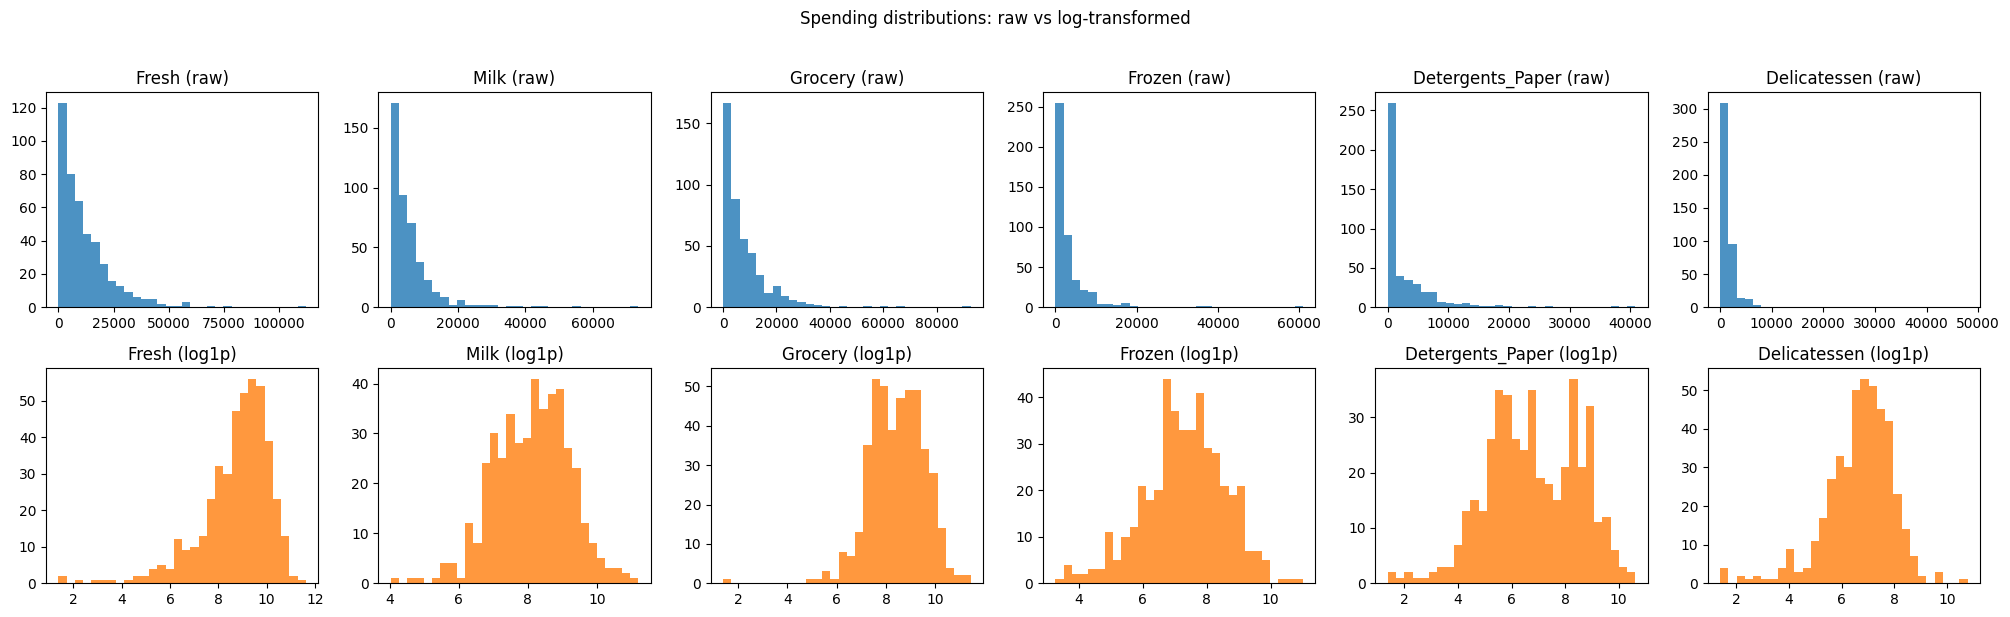

In [4]:
skew_table = pd.DataFrame({
    "Skewness (raw)": wholesale[SPEND_COLS].skew(),
    "Skewness (log1p)": np.log1p(wholesale[SPEND_COLS]).skew()
}).round(2)

print(skew_table)

fig, axes = plt.subplots(2, 6, figsize=(20, 6))

for i, col in enumerate(SPEND_COLS):
    axes[0, i].hist(wholesale[col], bins=30, alpha=0.8)
    axes[0, i].set_title(f"{col} (raw)")

    axes[1, i].hist(np.log1p(wholesale[col]), bins=30, alpha=0.8, color="tab:orange")
    axes[1, i].set_title(f"{col} (log1p)")

plt.suptitle("Spending distributions: raw vs log-transformed", y=1.02)
plt.tight_layout()
plt.show()

## 3.3 Preprocessing

Two versions of the feature matrix are prepared:

1. **`X_log`** — `log1p` transform, then standardisation (**main pipeline**)
2. **`X_raw`** — standardisation only (used later in the **ablation study**, Section 3.9)

Standardisation (mean 0, std 1) is needed because DBSCAN uses Euclidean distance: without it, the feature with the largest spending range (usually Fresh) would dominate every distance calculation.

In [5]:
# Proxy ground truth — used for ARI/NMI only, never for clustering
y_channel = wholesale["Channel"].values

X_log = StandardScaler().fit_transform(np.log1p(wholesale[SPEND_COLS]))
X_raw = StandardScaler().fit_transform(wholesale[SPEND_COLS])

N_FEATURES = X_log.shape[1]

print("X_log shape:", X_log.shape)
print("X_raw shape:", X_raw.shape)

X_log shape: (440, 6)
X_raw shape: (440, 6)


### Helper functions

These functions are written to be **dataset-agnostic**, so the same code can be reused for the Dry Bean section by changing `X` and `y_true`.

- `evaluate_clustering` — computes ARI, NMI, Silhouette (non-noise points), number of clusters and % noise
- `timed_fit` — fits a model several times and returns the labels and the median fit time
- `k_distance_curve` / `find_elbow` — implement the k-distance graph method from the lecture slides for choosing `eps`
- `dbscan_grid` / `select_dbscan_params` — run DBSCAN over a grid of parameters and select a setting using **internal metrics only** (no labels), so the ground truth is never used for tuning

In [6]:
def evaluate_clustering(X, labels, y_true=None, fit_time=None):
    labels = np.asarray(labels)
    mask = labels != -1

    cluster_ids, cluster_sizes = np.unique(labels[mask], return_counts=True)
    n_clusters = len(cluster_ids)

    # Silhouette is undefined for fewer than 2 clusters
    if n_clusters >= 2 and mask.sum() > n_clusters:
        sil = silhouette_score(X[mask], labels[mask])
    else:
        sil = np.nan

    result = {
        "Clusters": n_clusters,
        "Noise (%)": 100 * (~mask).mean(),
        "Smallest cluster": int(cluster_sizes.min()) if n_clusters else 0,
        "Silhouette": sil
    }

    if y_true is not None:
        result["ARI"] = adjusted_rand_score(y_true, labels)
        result["NMI"] = normalized_mutual_info_score(y_true, labels)

    if fit_time is not None:
        result["Time (ms)"] = 1000 * fit_time

    return result


def timed_fit(model, X, n_repeats=5):
    times = []
    for _ in range(n_repeats):
        start = time.perf_counter()
        labels = model.fit_predict(X)
        times.append(time.perf_counter() - start)
    return labels, float(np.median(times))


def k_distance_curve(X, k):
    # Average distance from each point to its k nearest neighbours (excluding itself),
    # sorted in ascending order - as described in the lecture slides
    nn = NearestNeighbors(n_neighbors=k + 1).fit(X)
    distances, _ = nn.kneighbors(X)
    return np.sort(distances[:, 1:].mean(axis=1))


def find_elbow(curve):
    # Elbow = point furthest from the straight line joining the first and last points
    # (both axes rescaled to [0, 1] so neither dominates)
    x = np.linspace(0, 1, len(curve))
    y = (curve - curve.min()) / (curve.max() - curve.min())
    distance_to_line = np.abs(y - x) / np.sqrt(2)
    return int(np.argmax(distance_to_line))


def dbscan_grid(X, eps_values, min_samples_values, y_true=None):
    rows = []
    for ms in min_samples_values:
        for eps in eps_values:
            labels = DBSCAN(eps=eps, min_samples=ms).fit_predict(X)
            rows.append({
                "min_samples": ms,
                "eps": round(float(eps), 3),
                **evaluate_clustering(X, labels, y_true)
            })
    return pd.DataFrame(rows)


def select_dbscan_params(grid, n_points, max_noise=20, min_cluster_frac=0.05):
    # Pick the highest-silhouette setting that has >= 2 clusters, limited noise
    # and no tiny clusters. Returns None if nothing qualifies.
    candidates = grid[
        (grid["Clusters"] >= 2)
        & (grid["Noise (%)"] <= max_noise)
        & (grid["Smallest cluster"] >= min_cluster_frac * n_points)
    ].dropna(subset=["Silhouette"])

    if candidates.empty:
        return None

    best = candidates.sort_values("Silhouette", ascending=False).iloc[0]
    return float(best["eps"]), int(best["min_samples"])


print("Helper functions defined.")

Helper functions defined.


## 3.4 Parameter Selection — k-distance Graph

DBSCAN has two parameters:

- **`min_samples` (MinPts)** — minimum number of points in a neighbourhood for a point to be a core point. A common rule of thumb is `2 × number of features` (= 12 here). Smaller values (4, 8) are also shown for comparison.
- **`eps`** — neighbourhood radius. Following the lecture slides: for each point compute the average distance to its K nearest neighbours (K = MinPts), sort the values and plot them; the **elbow** of the curve is a good `eps`.

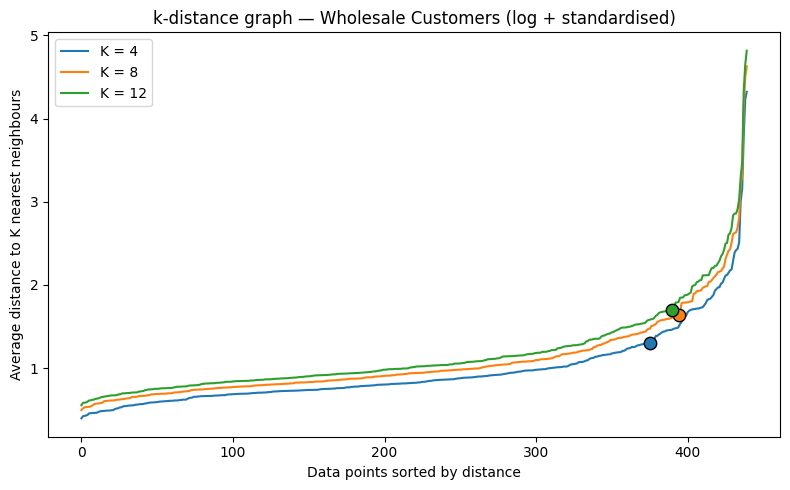

Suggested eps from elbow:
  MinPts =  4: eps ~ 1.3
  MinPts =  8: eps ~ 1.63
  MinPts = 12: eps ~ 1.7


In [7]:
MIN_PTS_DEFAULT = 2 * N_FEATURES
k_values = [4, 8, MIN_PTS_DEFAULT]

suggested_eps = {}

fig, ax = plt.subplots(figsize=(8, 5))

for k in k_values:
    curve = k_distance_curve(X_log, k)
    elbow_idx = find_elbow(curve)
    suggested_eps[k] = round(float(curve[elbow_idx]), 2)

    ax.plot(curve, label=f"K = {k}")
    ax.scatter(elbow_idx, curve[elbow_idx], s=80, edgecolor="black", zorder=3)

ax.set_title("k-distance graph — Wholesale Customers (log + standardised)")
ax.set_xlabel("Data points sorted by distance")
ax.set_ylabel("Average distance to K nearest neighbours")
ax.legend()
plt.tight_layout()
plt.show()

print("Suggested eps from elbow:")
for k, e in suggested_eps.items():
    print(f"  MinPts = {k:>2}: eps ~ {e}")

## 3.5 Parameter Sensitivity

The elbow gives a starting point, but the brief asks us to **analyse the parameter settings**. DBSCAN is run over a grid of `eps` and `min_samples` values and four quantities are tracked:

- number of clusters found
- % of points labelled as noise
- Silhouette score (non-noise points)
- ARI against Channel (shown for analysis only — **not** used to choose parameters)

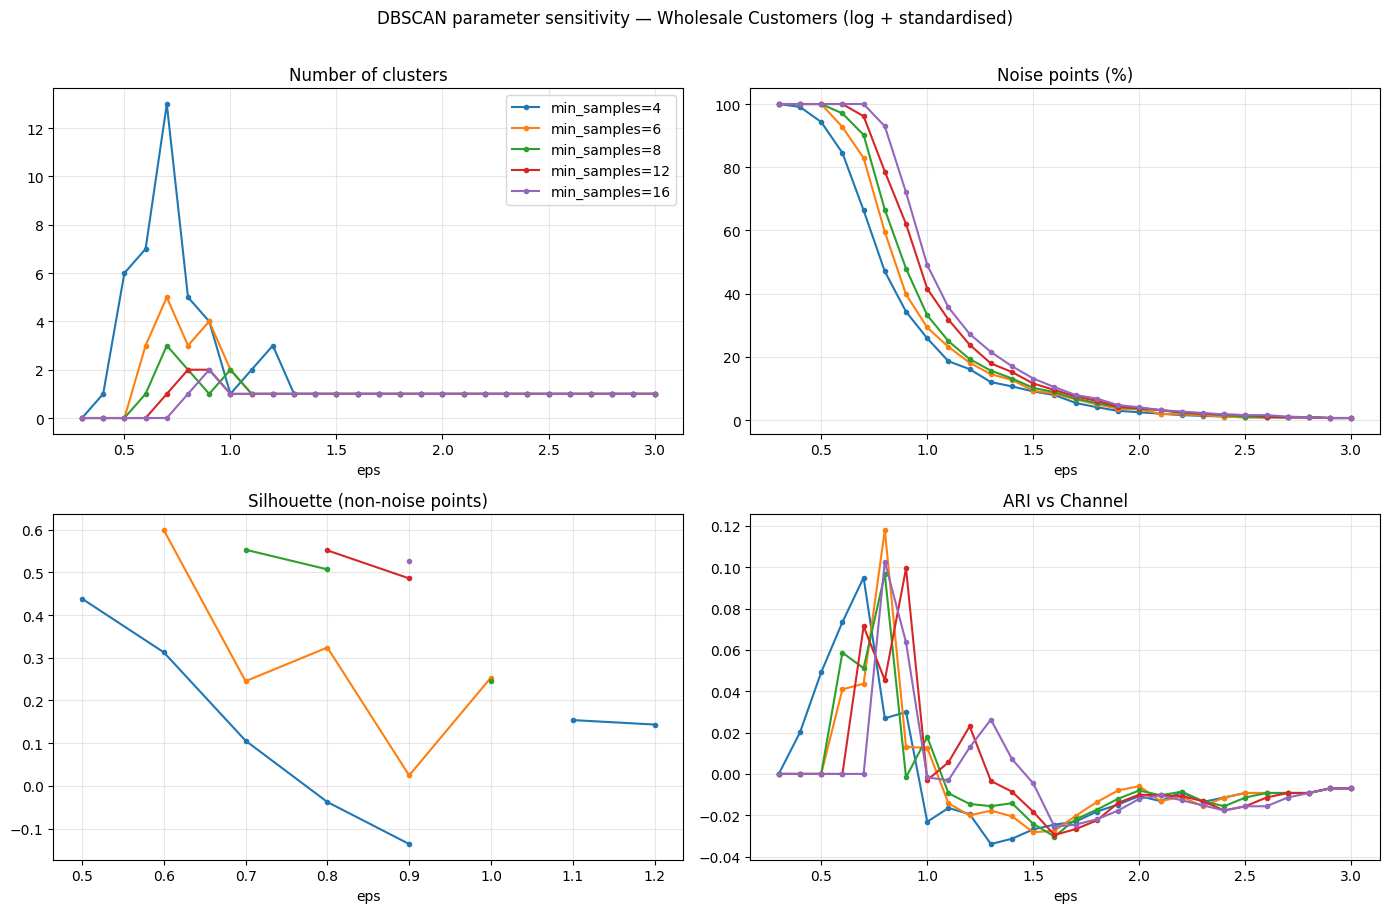

In [8]:
EPS_VALUES = np.round(np.arange(0.3, 3.01, 0.1), 2)
MIN_SAMPLES_VALUES = [4, 6, 8, 12, 16]

grid_log = dbscan_grid(X_log, EPS_VALUES, MIN_SAMPLES_VALUES, y_true=y_channel)

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
panels = [
    ("Clusters", "Number of clusters"),
    ("Noise (%)", "Noise points (%)"),
    ("Silhouette", "Silhouette (non-noise points)"),
    ("ARI", "ARI vs Channel")
]

for ax, (col, title) in zip(axes.ravel(), panels):
    for ms in MIN_SAMPLES_VALUES:
        subset = grid_log[grid_log["min_samples"] == ms]
        ax.plot(subset["eps"], subset[col], marker="o", markersize=3, label=f"min_samples={ms}")
    ax.set_title(title)
    ax.set_xlabel("eps")
    ax.grid(alpha=0.3)

axes[0, 0].legend()
plt.suptitle("DBSCAN parameter sensitivity — Wholesale Customers (log + standardised)", y=1.01)
plt.tight_layout()
plt.show()

### Selecting the final parameters

Parameters are chosen using **internal criteria only** (no labels), because in a real unsupervised task the true groups are unknown:

1. at least 2 clusters
2. no more than 20% of points labelled as noise
3. no cluster smaller than 5% of the data
4. among those, the highest Silhouette score

If no setting satisfies all conditions, the notebook falls back to the k-distance elbow (`min_samples = 12`). **Whether a fallback was needed is itself a finding** — it means the data has no clear multi-cluster density structure.

You can override `BEST_EPS` / `BEST_MIN_SAMPLES` manually after reviewing the plots above.

In [9]:
selection = select_dbscan_params(grid_log, n_points=len(X_log))

if selection is not None:
    BEST_EPS, BEST_MIN_SAMPLES = selection
    print("Selected by internal criteria.")
else:
    BEST_MIN_SAMPLES = MIN_PTS_DEFAULT
    BEST_EPS = suggested_eps[MIN_PTS_DEFAULT]
    print("No setting met all criteria -> falling back to k-distance elbow.")

print(f"eps = {BEST_EPS}, min_samples = {BEST_MIN_SAMPLES}")

# Top 10 multi-cluster settings by silhouette (for the report appendix / discussion)
grid_log.dropna(subset=["Silhouette"]).sort_values("Silhouette", ascending=False).head(10).round(3)

No setting met all criteria -> falling back to k-distance elbow.
eps = 1.7, min_samples = 12


,min_samples,eps,Clusters,Noise (%),Smallest cluster,Silhouette,ARI,NMI
31,6,0.6,3,92.727,7,0.599,0.041,0.086
60,8,0.7,3,90.227,8,0.553,0.051,0.103
89,12,0.8,2,78.636,44,0.552,0.045,0.135
118,16,0.9,2,72.045,61,0.527,0.064,0.149
61,8,0.8,2,66.591,70,0.507,0.097,0.189
90,12,0.9,2,62.045,78,0.486,0.099,0.179
2,4,0.5,6,94.318,3,0.439,0.049,0.077
33,6,0.8,3,59.545,7,0.324,0.118,0.213
3,4,0.6,7,84.545,2,0.313,0.073,0.122
35,6,1.0,2,29.318,11,0.254,0.013,0.031


### Trade-off: number of clusters vs noise

On real data, DBSCAN often finds several clusters **only** when `eps` is small — but a small `eps` also turns many clients into noise. The plot below shows every grid setting: how many clusters it found against how much of the data it discarded. The table gives the **lowest noise % at which each number of clusters was achieved**.

,Lowest noise (%)
Clusters,
2,18.6
3,16.1
4,34.3
5,47.0
6,94.3
7,84.5
13,66.4


To obtain 2+ clusters, DBSCAN had to label at least 16.1% of clients as noise.


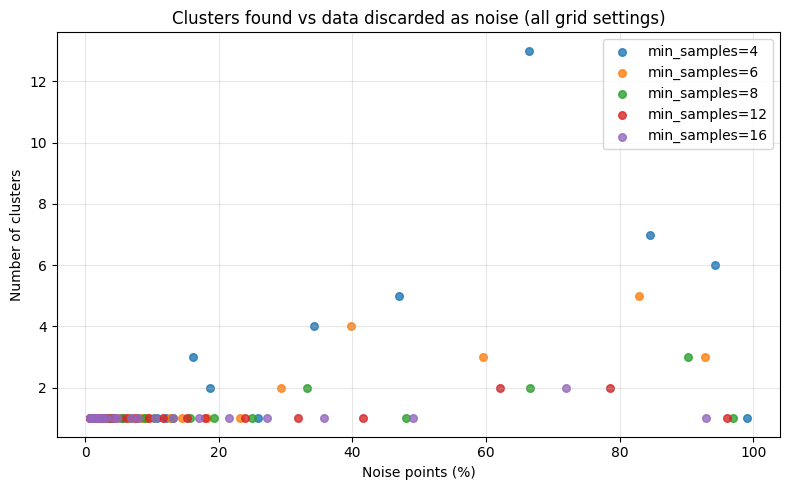

In [10]:
multi = grid_log[grid_log["Clusters"] >= 2]

if multi.empty:
    MIN_NOISE_FOR_2PLUS = np.nan
    print("No parameter setting produced 2 or more clusters.")
else:
    MIN_NOISE_FOR_2PLUS = multi["Noise (%)"].min()
    tradeoff = multi.groupby("Clusters")["Noise (%)"].min().round(1).rename("Lowest noise (%)")
    display(tradeoff.to_frame())
    print(f"To obtain 2+ clusters, DBSCAN had to label at least {MIN_NOISE_FOR_2PLUS:.1f}% of clients as noise.")

fig, ax = plt.subplots(figsize=(8, 5))
for ms in MIN_SAMPLES_VALUES:
    subset = grid_log[(grid_log["min_samples"] == ms) & (grid_log["Clusters"] > 0)]
    ax.scatter(subset["Noise (%)"], subset["Clusters"], s=30, alpha=0.8, label=f"min_samples={ms}")
ax.set_xlabel("Noise points (%)")
ax.set_ylabel("Number of clusters")
ax.set_title("Clusters found vs data discarded as noise (all grid settings)")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

## 3.6 Final DBSCAN Run and Evaluation

In [11]:
dbscan_final = DBSCAN(eps=BEST_EPS, min_samples=BEST_MIN_SAMPLES)
y_dbscan, t_dbscan = timed_fit(dbscan_final, X_log)

dbscan_metrics = evaluate_clustering(X_log, y_dbscan, y_channel, fit_time=t_dbscan)

print("DBSCAN Results — Wholesale Customers")
print("-" * 70)
print(f"{'Clusters':>9} {'Noise %':>9} {'ARI':>8} {'NMI':>8} {'Silhouette':>11} {'Time (ms)':>10}")
print("-" * 70)
sil_text = "n/a" if np.isnan(dbscan_metrics["Silhouette"]) else f"{dbscan_metrics['Silhouette']:.3f}"

print(
    f"{dbscan_metrics['Clusters']:>9}"
    f"{dbscan_metrics['Noise (%)']:>9.1f}"
    f"{dbscan_metrics['ARI']:>9.3f}"
    f"{dbscan_metrics['NMI']:>9.3f}"
    f"{sil_text:>11}"
    f"{dbscan_metrics['Time (ms)']:>10.2f}"
)

if np.isnan(dbscan_metrics["Silhouette"]):
    print("\nSilhouette is undefined: DBSCAN found fewer than 2 clusters.")

print("\nPoints per cluster (-1 = noise):")
print(pd.Series(y_dbscan).value_counts().sort_index())

DBSCAN Results — Wholesale Customers
----------------------------------------------------------------------
 Clusters   Noise %      ARI      NMI  Silhouette  Time (ms)
----------------------------------------------------------------------
        1      7.5   -0.027    0.009        n/a      3.50

Silhouette is undefined: DBSCAN found fewer than 2 clusters.

Points per cluster (-1 = noise):
-1     33
 0    407
Name: count, dtype: int64


## 3.7 Visualisation

The six features are projected onto 2 dimensions with PCA **for plotting only** (clustering was done on all six features).

Left: DBSCAN clusters (noise shown as grey crosses). Right: the Channel proxy labels.

Variance explained by 2 PCs: 71.3%


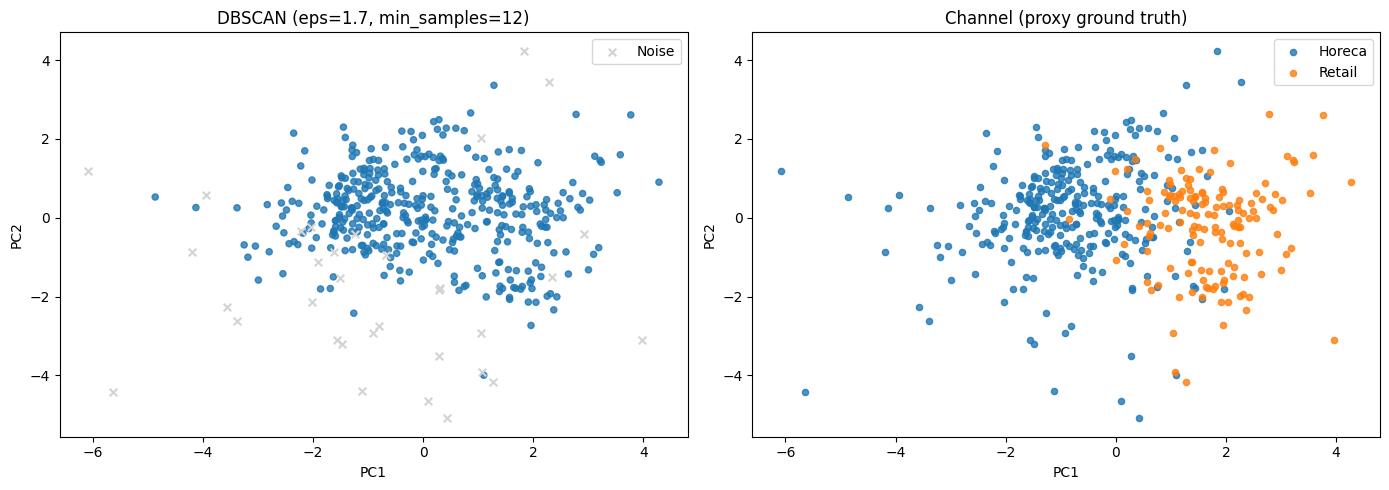

In [12]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_log_2d = pca.fit_transform(X_log)

print(f"Variance explained by 2 PCs: {pca.explained_variance_ratio_.sum():.1%}")


def plot_clusters(ax, X2d, labels, title):
    labels = np.asarray(labels)
    noise = labels == -1
    ax.scatter(X2d[~noise, 0], X2d[~noise, 1], c=labels[~noise], cmap="tab10", s=20, alpha=0.8)
    if noise.any():
        ax.scatter(X2d[noise, 0], X2d[noise, 1], c="lightgrey", marker="x", s=30, label="Noise")
        ax.legend(loc="best")
    ax.set_title(title)
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")


fig, axes = plt.subplots(1, 2, figsize=(14, 5))

plot_clusters(
    axes[0], X_log_2d, y_dbscan,
    f"DBSCAN (eps={BEST_EPS}, min_samples={BEST_MIN_SAMPLES})"
)

for ch, name in CHANNEL_NAMES.items():
    idx = y_channel == ch
    axes[1].scatter(X_log_2d[idx, 0], X_log_2d[idx, 1], s=20, alpha=0.8, label=name)
axes[1].set_title("Channel (proxy ground truth)")
axes[1].set_xlabel("PC1")
axes[1].set_ylabel("PC2")
axes[1].legend()

plt.tight_layout()
plt.show()

### Cluster profiles

What does each cluster actually *mean*? The table shows the **median annual spending** per cluster (original monetary units), and the cross-tab shows how each cluster splits by Channel.

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicatessen,Size
Cluster,,,,,,,
0,8708.0,3683.0,4754.0,1668.0,828.0,1000.0,407
Noise,1869.0,1534.0,5091.0,774.0,409.0,127.0,33


Channel,Horeca,Retail,All
Cluster,,,
0,271,136,407
Noise,27,6,33
All,298,142,440


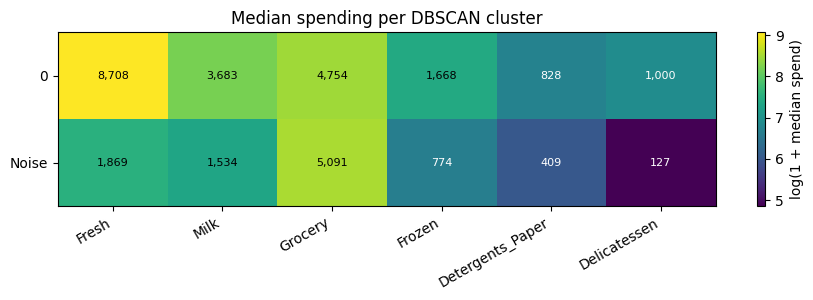

In [13]:
profile = wholesale[SPEND_COLS].copy()
profile["Cluster"] = np.where(y_dbscan == -1, "Noise", y_dbscan.astype(str))

median_profile = profile.groupby("Cluster")[SPEND_COLS].median().round(0)
median_profile["Size"] = profile["Cluster"].value_counts()
display(median_profile)

channel_crosstab = pd.crosstab(
    profile["Cluster"],
    wholesale["Channel"].map(CHANNEL_NAMES),
    margins=True
)
display(channel_crosstab)

# Heatmap: median log-spending per cluster
heat = np.log1p(profile.groupby("Cluster")[SPEND_COLS].median())

fig, ax = plt.subplots(figsize=(9, 0.8 * len(heat) + 1.5))
im = ax.imshow(heat.values, cmap="viridis", aspect="auto")
ax.set_xticks(range(len(SPEND_COLS)))
ax.set_xticklabels(SPEND_COLS, rotation=30, ha="right")
ax.set_yticks(range(len(heat)))
ax.set_yticklabels(heat.index)
midpoint = (heat.values.min() + heat.values.max()) / 2
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        value = heat.values[i, j]
        ax.text(j, i, f"{np.expm1(value):,.0f}", ha="center", va="center", fontsize=8,
                color="black" if value > midpoint else "white")
plt.colorbar(im, ax=ax, label="log(1 + median spend)")
ax.set_title("Median spending per DBSCAN cluster")
plt.tight_layout()
plt.show()

## 3.8 Noise / Outlier Analysis

A key property of DBSCAN is that it does **not** force every point into a cluster. Here we check *who* the noise points are — if they are mostly extreme or unusual spenders, DBSCAN is acting as a useful outlier detector (a success case). If they look like ordinary clients, `eps` is probably too small (a failure case).

Noise points: 33 of 440 (7.5%)


,Clustered (median),Noise (median),Ratio noise / clustered
Fresh,8708.0,1869.0,0.21
Milk,3683.0,1534.0,0.42
Grocery,4754.0,5091.0,1.07
Frozen,1668.0,774.0,0.46
Detergents_Paper,828.0,409.0,0.49
Delicatessen,1000.0,127.0,0.13


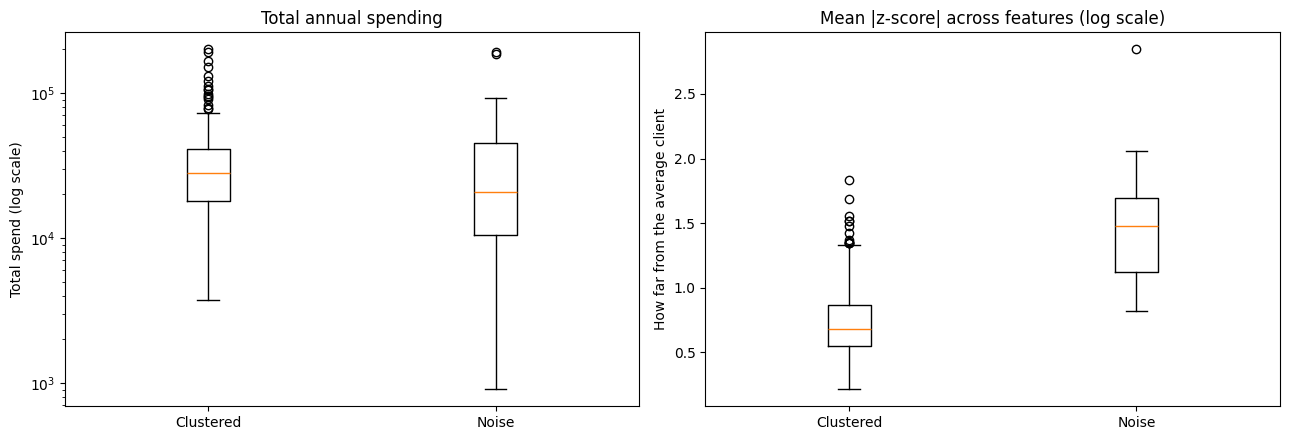

Noise points by Channel:
Channel
Horeca    27
Retail     6
Name: count, dtype: int64


In [14]:
is_noise = y_dbscan == -1
total_spend = wholesale[SPEND_COLS].sum(axis=1)

print(f"Noise points: {is_noise.sum()} of {len(is_noise)} ({100 * is_noise.mean():.1f}%)")

if is_noise.any():
    comparison = pd.DataFrame({
        "Clustered (median)": wholesale.loc[~is_noise, SPEND_COLS].median(),
        "Noise (median)": wholesale.loc[is_noise, SPEND_COLS].median()
    }).round(0)
    comparison["Ratio noise / clustered"] = (comparison["Noise (median)"] / comparison["Clustered (median)"]).round(2)
    display(comparison)

    # How "extreme" are noise points? Mean |z-score| across features (log scale)
    extremeness = np.abs(X_log).mean(axis=1)

    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

    axes[0].boxplot([total_spend[~is_noise], total_spend[is_noise]])
    axes[0].set_xticks([1, 2])
    axes[0].set_xticklabels(["Clustered", "Noise"])
    axes[0].set_yscale("log")
    axes[0].set_title("Total annual spending")
    axes[0].set_ylabel("Total spend (log scale)")

    axes[1].boxplot([extremeness[~is_noise], extremeness[is_noise]])
    axes[1].set_xticks([1, 2])
    axes[1].set_xticklabels(["Clustered", "Noise"])
    axes[1].set_title("Mean |z-score| across features (log scale)")
    axes[1].set_ylabel("How far from the average client")

    plt.tight_layout()
    plt.show()

    print("Noise points by Channel:")
    print(wholesale.loc[is_noise, "Channel"].map(CHANNEL_NAMES).value_counts())
else:
    print("DBSCAN labelled no points as noise with these parameters.")

## 3.9 Ablation Study — Effect of the Log Transform

The log transform is the key preprocessing component. To measure its effect, the **same parameter search and selection procedure** is repeated on `X_raw` (standardised only, no log). Each version gets its own best parameters, so the comparison is fair.

Raw: no setting met all criteria -> falling back to k-distance elbow.


,Preprocessing,eps,min_samples,Clusters,Noise (%),Smallest cluster,Silhouette,ARI,NMI,Time (ms)
0,Standardise only (no log),1.72,12,1,5.0,418,NaN,0.033,0.013,3.695
1,log1p + standardise,1.70,12,1,7.5,407,NaN,-0.027,0.009,3.501


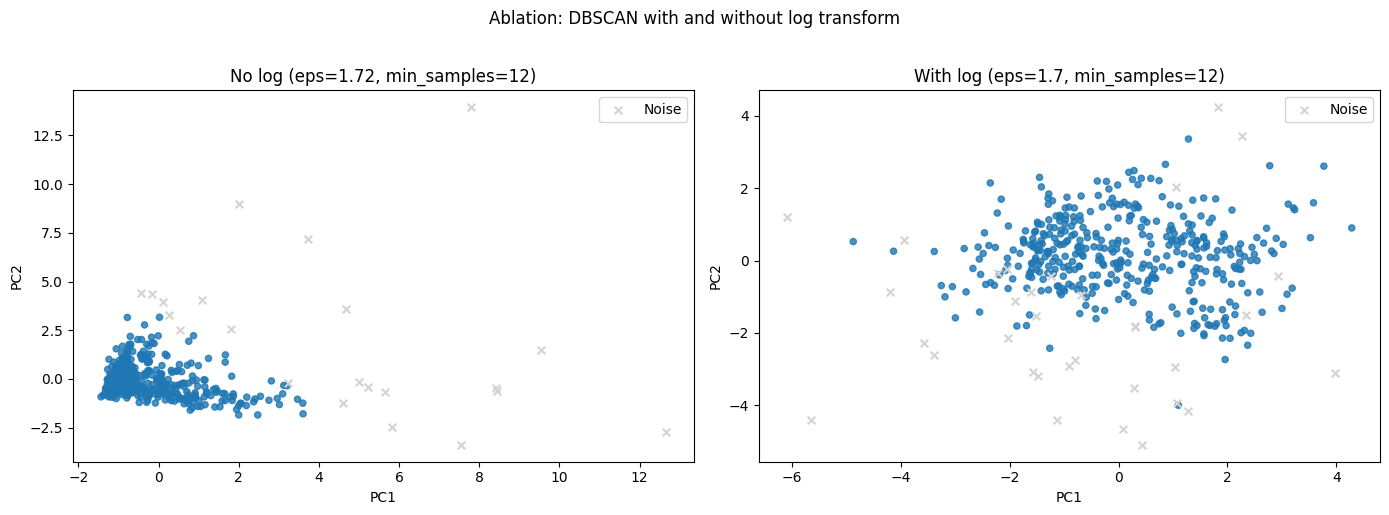

In [15]:
grid_raw = dbscan_grid(X_raw, EPS_VALUES, MIN_SAMPLES_VALUES, y_true=y_channel)
selection_raw = select_dbscan_params(grid_raw, n_points=len(X_raw))

if selection_raw is not None:
    EPS_RAW, MS_RAW = selection_raw
    print("Raw: selected by internal criteria.")
else:
    MS_RAW = MIN_PTS_DEFAULT
    curve_raw = k_distance_curve(X_raw, MS_RAW)
    EPS_RAW = round(float(curve_raw[find_elbow(curve_raw)]), 2)
    print("Raw: no setting met all criteria -> falling back to k-distance elbow.")

y_dbscan_raw, t_dbscan_raw = timed_fit(DBSCAN(eps=EPS_RAW, min_samples=MS_RAW), X_raw)

ablation = pd.DataFrame([
    {"Preprocessing": "Standardise only (no log)", "eps": EPS_RAW, "min_samples": MS_RAW,
     **evaluate_clustering(X_raw, y_dbscan_raw, y_channel, t_dbscan_raw)},
    {"Preprocessing": "log1p + standardise", "eps": BEST_EPS, "min_samples": BEST_MIN_SAMPLES,
     **evaluate_clustering(X_log, y_dbscan, y_channel, t_dbscan)}
])

display(ablation.round(3))

# Side-by-side PCA plots
X_raw_2d = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(X_raw)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot_clusters(axes[0], X_raw_2d, y_dbscan_raw, f"No log (eps={EPS_RAW}, min_samples={MS_RAW})")
plot_clusters(axes[1], X_log_2d, y_dbscan, f"With log (eps={BEST_EPS}, min_samples={BEST_MIN_SAMPLES})")
plt.suptitle("Ablation: DBSCAN with and without log transform", y=1.02)
plt.tight_layout()
plt.show()

## 3.10 Context: DBSCAN vs K-Means vs HDBSCAN on Wholesale Customers

To put the DBSCAN result in context, K-Means and HDBSCAN are run on the **same preprocessed data** (`X_log`):

- **K-Means (k = 2)** — matches the number of Channel groups
- **K-Means (best k)** — k from 2–8 chosen by Silhouette (no labels used)
- **HDBSCAN** — `min_cluster_size` set equal to DBSCAN's `min_samples` for a like-for-like comparison

*(Drop this subsection if the group decides the real-data sections should cover DBSCAN only.)*

Best k by silhouette: 2


,Algorithm,Clusters,Noise (%),Smallest cluster,Silhouette,ARI,NMI,Time (ms)
0,K-Means (k=2),2,0.000,188,0.290,0.514,0.445,16.021
1,DBSCAN,1,7.500,407,NaN,-0.027,0.009,3.884
2,HDBSCAN,2,82.273,39,0.576,0.051,0.126,4.356


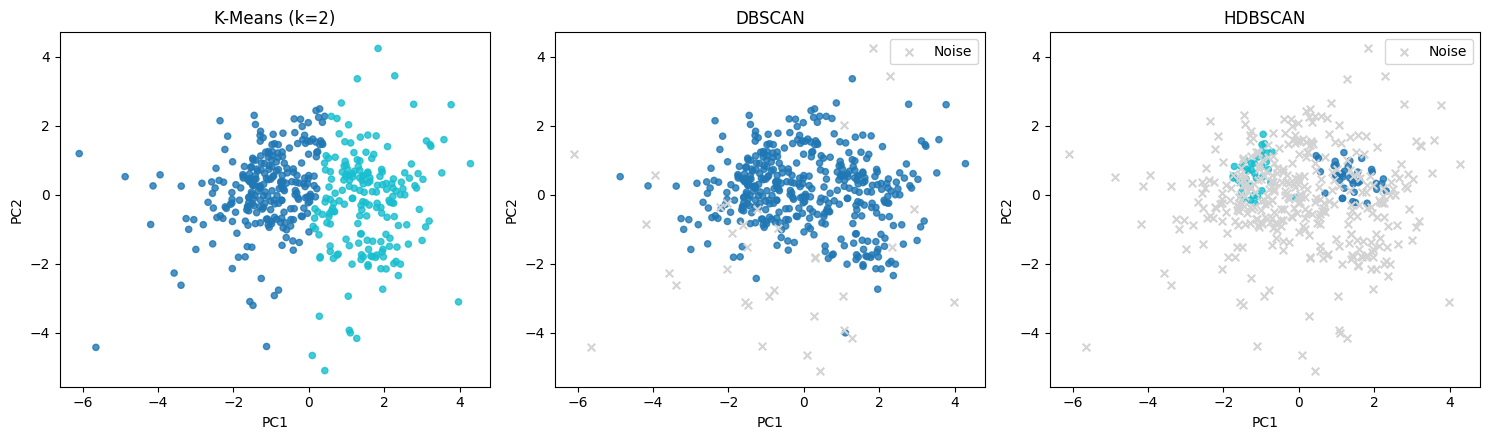

In [16]:
# K-Means with k chosen by silhouette
k_range = range(2, 9)
kmeans_sil = []
for k in k_range:
    labels_k = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit_predict(X_log)
    kmeans_sil.append(silhouette_score(X_log, labels_k))
BEST_K = list(k_range)[int(np.argmax(kmeans_sil))]
print(f"Best k by silhouette: {BEST_K}")

models = {"K-Means (k=2)": KMeans(n_clusters=2, n_init=10, random_state=RANDOM_STATE)}
if BEST_K != 2:
    models[f"K-Means (k={BEST_K})"] = KMeans(n_clusters=BEST_K, n_init=10, random_state=RANDOM_STATE)
models["DBSCAN"] = DBSCAN(eps=BEST_EPS, min_samples=BEST_MIN_SAMPLES)
models["HDBSCAN"] = HDBSCAN(min_cluster_size=BEST_MIN_SAMPLES)

comparison_rows = []
comparison_labels = {}

for name, model in models.items():
    labels_m, t_m = timed_fit(model, X_log)
    comparison_labels[name] = labels_m
    comparison_rows.append({"Algorithm": name, **evaluate_clustering(X_log, labels_m, y_channel, t_m)})

wholesale_results = pd.DataFrame(comparison_rows)
display(wholesale_results.round(3))

fig, axes = plt.subplots(1, len(models), figsize=(5 * len(models), 4.5))
for ax, (name, labels_m) in zip(axes, comparison_labels.items()):
    plot_clusters(ax, X_log_2d, labels_m, name)
plt.tight_layout()
plt.show()

## 3.11 Auto-generated Summary of Key Numbers

This cell turns the results above into plain sentences, so the numbers quoted in the report always match what the notebook produced.

In [17]:
m = dbscan_metrics
lines = [
    f"- Log transform reduced average feature skewness from {skew_table['Skewness (raw)'].mean():.2f} "
    f"to {skew_table['Skewness (log1p)'].mean():.2f}.",
    f"- Selected DBSCAN parameters: eps = {BEST_EPS}, min_samples = {BEST_MIN_SAMPLES} "
    f"({'internal-criteria selection' if selection is not None else 'k-distance elbow fallback'}).",
    f"- DBSCAN found {m['Clusters']} cluster(s) and labelled {m['Noise (%)']:.1f}% of clients as noise.",
    f"- Against Channel: ARI = {m['ARI']:.3f}, NMI = {m['NMI']:.3f}. Silhouette (non-noise) = "
    f"{'n/a (fewer than 2 clusters)' if np.isnan(m['Silhouette']) else format(m['Silhouette'], '.3f')}. "
    f"Fit time = {m['Time (ms)']:.2f} ms.",
]

if np.isnan(MIN_NOISE_FOR_2PLUS):
    lines.append("- No eps/min_samples setting in the grid produced 2 or more clusters.")
else:
    lines.append(f"- Getting 2+ clusters required labelling at least {MIN_NOISE_FOR_2PLUS:.1f}% of clients as noise.")

if is_noise.any():
    ratio = total_spend[is_noise].median() / total_spend[~is_noise].median()
    lines.append(f"- Median total spending of noise clients is {ratio:.2f}x that of clustered clients.")

abl_raw, abl_log = ablation.iloc[0], ablation.iloc[1]
lines.append(
    f"- Ablation: without log -> {abl_raw['Clusters']} cluster(s), {abl_raw['Noise (%)']:.1f}% noise, ARI {abl_raw['ARI']:.3f}; "
    f"with log -> {abl_log['Clusters']} cluster(s), {abl_log['Noise (%)']:.1f}% noise, ARI {abl_log['ARI']:.3f}."
)

best_ari_row = wholesale_results.loc[wholesale_results["ARI"].idxmax()]
lines.append(f"- Highest ARI vs Channel among all algorithms: {best_ari_row['Algorithm']} ({best_ari_row['ARI']:.3f}).")

print("\n".join(lines))

- Log transform reduced average feature skewness from 5.15 to -0.69.
- Selected DBSCAN parameters: eps = 1.7, min_samples = 12 (k-distance elbow fallback).
- DBSCAN found 1 cluster(s) and labelled 7.5% of clients as noise.
- Against Channel: ARI = -0.027, NMI = 0.009. Silhouette (non-noise) = n/a (fewer than 2 clusters). Fit time = 3.50 ms.
- Getting 2+ clusters required labelling at least 16.1% of clients as noise.
- Median total spending of noise clients is 0.75x that of clustered clients.
- Ablation: without log -> 1 cluster(s), 5.0% noise, ARI 0.033; with log -> 1 cluster(s), 7.5% noise, ARI -0.027.
- Highest ARI vs Channel among all algorithms: K-Means (k=2) (0.514).


## 3.12 Discussion Guide (fill in after running)

Use the outputs above to answer each point in the report. Prompts only — write the actual findings from your run.

**Parameter sensitivity (3.4–3.5)**
- How sharply does the number of clusters / % noise change as `eps` moves? Is there a stable range or a narrow "sweet spot"?
- Did the selection need the fallback? If yes: the spending data has one dense core with sparse surroundings rather than several separated dense regions — link to the lecture point that DBSCAN struggles when density varies.

**Cluster meaning (3.7)**
- Using the median-spending table, describe each cluster in business terms (e.g. "high Grocery + Detergents_Paper" ≈ retail-like buyers; "high Fresh + Frozen" ≈ restaurant-like buyers).
- How well does it line up with Channel (cross-tab, ARI/NMI)? Remember Channel is only a proxy — spending behaviour need not match business type exactly.

**Noise points (3.8)**
- Are noise clients extreme spenders, unusual mixes, or ordinary clients? Success case vs failure case.
- How does treating noise as its own group affect ARI/NMI?

**Ablation (3.9)**
- What changed without the log transform (clusters, noise %, which clients become noise)? Connect to the skewness table in 3.2.

**Comparison (3.10)**
- K-Means must assign every client — how do the big spenders affect its clusters compared with DBSCAN?
- Does HDBSCAN (which adapts to varying density) handle this data better than DBSCAN? Link to Section 2 synthetic findings.
- Fit time differences — are they meaningful at 440 points?

**Limitations**
- Proxy labels; small dataset (440 clients); silhouette computed without noise can look optimistic when many points are removed.